# The Rosenbrock Banana

In *Exponential Decay*, a curved posterior arose
naturally from a physical model and a limited dataset. This tutorial goes in
the opposite direction. We pick the posterior we want, the
Rosenbrock valley, bent until it hooks back into a "U", and build a model
and a dataset that produce it. We then check whether pypolymix can recover it from the data.

We compare three variational families against the exact posterior:

* `IIDGaussianGroup` (mean-field Gaussian),
* `GaussianGroup` (full-covariance Gaussian),
* `LangevinGroup` (a trained Langevin sampler, with no fixed shape).

**When is a posterior non-Gaussian?** If a model is *linear* in its
stochastic parameters (a polynomial chaos expansion, or the last layer of a
neural network) and the noise and prior are Gaussian, the log posterior is a
quadratic function of the parameters. Its posterior is then exactly
Gaussian, whatever the data, and a full-covariance Gaussian is already
exact. The posterior becomes non-Gaussian when the parameters enter the model
*nonlinearly* and the data are not informative enough to make that
nonlinearity look locally linear. Then the posterior can bend, and that is
where a more flexible family such as `LangevinGroup` can pay off.

The code is the same as in *Exponential Decay*. Only the model, the data, and the grid
limits change.

## Setup

In [1]:
import math
import pathlib
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch.optim.lr_scheduler import OneCycleLR

from pypolymix import StochasticModel, elbo_loss
from pypolymix.likelihoods import GaussianLikelihood
from pypolymix.parameter_groups import GaussianGroup, IIDGaussianGroup, KNNEntropyKL, LangevinGroup
from pypolymix.parameter_groups.kl_estimators import _knn_entropy
from pypolymix.priors import GaussianPrior, IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, SurrogateModel

torch.set_default_dtype(torch.float64)
LOG2PI = math.log(2 * math.pi)
COLORS = {"exact": "0.3", "iid": "tab:blue", "full": "tab:green", "langevin": "tab:red"}
LABELS = {"exact": "Exact posterior", "iid": "Mean-field Gaussian", "full": "Full-covariance Gaussian",
          "langevin": "Langevin"}

## Working backwards: a model whose posterior is the Rosenbrock banana

Treated as a negative log density, the Rosenbrock function
$$\frac{(\theta_1 - 1)^2}{2\sigma_a^2} + \frac{(\theta_2 - \theta_1^2)^2}{2\sigma_b^2}$$
is a banana: $\theta_1$ is loosely determined, and for each $\theta_1$ the
second term forces $\theta_2 \approx \theta_1^2$. Read it as a least-squares
misfit: it is what you get from one measurement of $\theta_1$ (value 1, noise
$\sigma_a$) and one measurement of $\theta_2 - \theta_1^2$ (value 0, noise
$\sigma_b$). So we want a model that returns $\theta_1$ at one input and
$\theta_2 - \theta_1^2$ at another:
$$f(x;\theta) = \theta_1 (1 - x) + (\theta_2 - \theta_1^2)\, x,$$
which gives $f(0) = \theta_1$ and $f(1) = \theta_2 - \theta_1^2$. The model is
linear in $x$ but nonlinear in $\theta$, and that nonlinearity is what bends
the posterior.

As a pypolymix `SurrogateModel` it receives inputs of shape `(N, 1)` and
parameters of shape `(S, 2)`, and returns outputs of shape `(S, N, 1)`.

In [2]:
class RosenbrockModel(SurrogateModel):
    # f(x; theta) = theta1 (1 - x) + (theta2 - theta1^2) x.
    num_inputs, num_outputs = 1, 1

    def forward(self, x, params):
        # x: (N, 1), params: (S, 2)  ->  (S, N, 1)
        t1, t2 = params[:, None, :1], params[:, None, 1:]
        return t1 * (1 - x[None]) + (t2 - t1**2) * x[None]

    def num_params(self):
        return 2


surrogate = RosenbrockModel()

## The data

True parameters $\theta = (1, 1)$, noise $\sigma = 0.5$, and ten observations
spread over $x \in [0.7, 1]$, the upper part of the domain. There the weight
$1 - x$ on $\theta_1$ is at most 0.3, so the data mostly see
$\theta_2 - \theta_1^2$ and only weakly see $\theta_1$ itself:

* the valley $\theta_2 \approx \theta_1^2$ is pinned down precisely;
* the position along the valley, and even the *sign* of $\theta_1$, is only
  weakly identified, since $\theta_1$ and $-\theta_1$ give nearly the same
  predictions.

The result is a U-shaped valley whose right arm (the side of the true
parameters) carries more mass than the left. Measuring closer to $x = 0$
would pin $\theta_1$ down and leave the familiar one-armed banana.
Measuring only at $x = 1$ would make the U exactly symmetric.

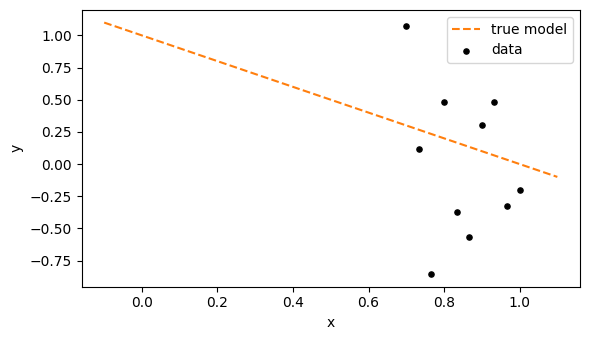

In [3]:
THETA_TRUE = torch.tensor([1.0, 1.0])
SIGMA = 0.5  # observation noise, assumed known
x_train = torch.linspace(0.7, 1.0, 10)[:, None]
N_TRAIN = x_train.shape[0]

g = torch.Generator().manual_seed(0)
with torch.no_grad():
    y_train = surrogate(x_train, THETA_TRUE[None])[0] + SIGMA * torch.randn(N_TRAIN, 1, generator=g)

x_plot = torch.linspace(-0.1, 1.1, 100)[:, None]
with torch.no_grad():
    f_true = surrogate(x_plot, THETA_TRUE[None])[0, :, 0]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x_plot[:, 0], f_true, "--", color="tab:orange", label="true model")
ax.scatter(x_train[:, 0], y_train[:, 0], color="k", s=14, zorder=5, label="data")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.tight_layout()

## The exact posterior

With known noise $\sigma$ and a broad prior $\theta \sim N(0, 3^2 I)$, the
unnormalized log posterior is the log likelihood plus the log prior:
$$\log p(y, \theta) = -\sum_{i=1}^{N} \frac{(y_i - f(x_i;\theta))^2}{2\sigma^2}
- \frac{\|\theta\|^2}{2\cdot 3^2} + \text{const}.$$
The same prior is used by every variational family below, as a pypolymix
`IIDGaussianPrior`.

In [4]:
PRIOR_STD = 3.0
prior = IIDGaussianPrior(std=PRIOR_STD)


def log_joint(theta):
    # log p(y | theta) + log p(theta) for a batch of parameter vectors, (S, 2) -> (S,)
    f = surrogate(x_train, theta)
    log_lik = -0.5 * ((y_train[None] - f) ** 2).sum((-1, -2)) / SIGMA**2 - N_TRAIN * (math.log(SIGMA) + 0.5 * LOG2PI)
    log_prior = -0.5 * (theta**2).sum(-1) / PRIOR_STD**2 - 2 * (math.log(PRIOR_STD) + 0.5 * LOG2PI)
    return log_lik + log_prior

With only two parameters we do not need MCMC: we evaluate the log posterior on
a fine $800 \times 800$ grid. Summing the grid gives the normalizing constant
$\log Z = \log p(y)$, and with it the exact density, its entropy, and exact
samples (pick grid cells in proportion to their mass, then jitter uniformly
within the cell). This is the ground truth for the rest of the tutorial.

In [5]:
a = torch.linspace(-6, 6, 800)
b = torch.linspace(-4, 14, 800)
A_grid, B_grid = torch.meshgrid(a, b, indexing="ij")
grid = torch.stack([A_grid.flatten(), B_grid.flatten()], 1)
with torch.no_grad():
    lj = torch.cat([log_joint(chunk) for chunk in grid.split(100_000)])

cell = (a[1] - a[0]).item() * (b[1] - b[0]).item()
logZ = (torch.logsumexp(lj, 0) + math.log(cell)).item()
density = (lj - logZ).exp().reshape(800, 800)  # exact p(theta | y) on the grid

g = torch.Generator().manual_seed(0)
idx = torch.multinomial(density.flatten() / density.sum(), 100_000, replacement=True, generator=g)
jitter = (torch.rand(100_000, 2, generator=g) - 0.5) * torch.tensor([(a[1] - a[0]).item(), (b[1] - b[0]).item()])
theta_exact = grid[idx] + jitter
with torch.no_grad():
    H_exact = -(log_joint(theta_exact) - logZ).mean().item()

edge_mass = (density[0].sum() + density[-1].sum() + density[:, 0].sum() + density[:, -1].sum()).item() * cell
print(f"log Z = {logZ:.3f},  entropy H[p] = {H_exact:.3f} nats,  mass on the grid edge = {edge_mass:.1e}")
print(f"posterior mean = {theta_exact.mean(0).numpy().round(3)},  sd = {theta_exact.std(0).numpy().round(3)}")

log Z = -11.994,  entropy H[p] = 1.042 nats,  mass on the grid edge = 2.6e-09
posterior mean = [0.63  1.118],  sd = [0.911 1.308]


A small plotting helper draws the 50/90/99% highest-density contours of the
exact posterior, which we reuse to judge every approximation.

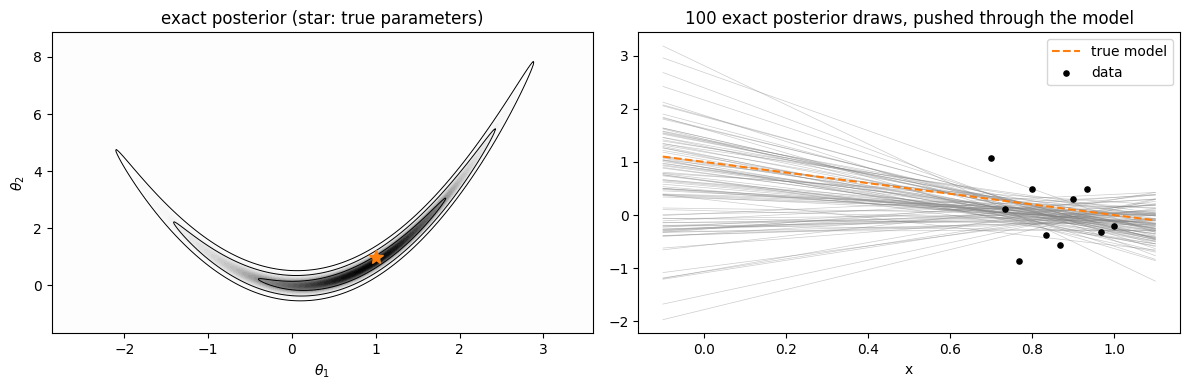

In [6]:
NAMES = [r"$\theta_1$", r"$\theta_2$"]
lo, hi = torch.quantile(theta_exact, 0.001, dim=0), torch.quantile(theta_exact, 0.999, dim=0)
PLOT_LIMS = list(zip((lo - 0.15 * (hi - lo)).tolist(), (hi + 0.15 * (hi - lo)).tolist()))

_d = density.flatten().sort(descending=True).values
_cum = _d.cumsum(0) / _d.sum()
LEVELS = [_d[(_cum >= m).nonzero()[0, 0]].item() for m in (0.99, 0.9, 0.5)]


def exact_contours(ax, filled=False):
    if filled:
        ax.contourf(a, b, density.T, levels=30, cmap="Greys")
    ax.contour(a, b, density.T, levels=LEVELS, colors="k", linewidths=0.7)
    ax.plot(*THETA_TRUE, "*", color="tab:orange", ms=10)
    ax.set_xlim(PLOT_LIMS[0])
    ax.set_ylim(PLOT_LIMS[1])
    ax.set_xlabel(NAMES[0])
    ax.set_ylabel(NAMES[1])


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
exact_contours(axes[0], filled=True)
axes[0].set_title("exact posterior (star: true parameters)")
with torch.no_grad():
    f_post = surrogate(x_plot, theta_exact[:100])[..., 0]
for f in f_post:
    axes[1].plot(x_plot[:, 0], f, color="0.5", lw=0.5, alpha=0.4)
axes[1].plot(x_plot[:, 0], f_true, "--", color="tab:orange", label="true model")
axes[1].scatter(x_train[:, 0], y_train[:, 0], color="k", s=14, zorder=5, label="data")
axes[1].set_xlabel("x")
axes[1].set_title("100 exact posterior draws, pushed through the model")
axes[1].legend()
plt.tight_layout()

**The bent banana, as designed.** The posterior follows the parabola
$\theta_2 \approx \theta_1^2$. Its right arm, through the true parameters,
holds most of the mass, and it hooks back over to $\theta_1 < 0$, where
the mirror-image parameters fit the data almost as well. In function space
(right), every posterior draw fits the data on $[0.7, 1]$, while the value
at $x = 0$, which is $\theta_1$, spreads widely and takes both signs.

## Fitting a stochastic model with pypolymix

Every family is trained with the same loop. A `StochasticModel` combines the
surrogate with a *parameter group* (the variational distribution $q$ over
$\theta$). Each epoch it draws `num_samples` parameter vectors, evaluates the
surrogate, and we minimize the negative ELBO
$$\mathcal{L}(q) = \mathbb{E}_q\big[-\log p(y\mid\theta)\big] + \mathrm{KL}\big(q\,\|\,p(\theta)\big),$$
computed by `elbo_loss` from the `GaussianLikelihood` NLL (here with the
noise frozen at its known value) and the group's `distribution_loss()`.

A useful identity: $\mathcal{L}(q) = \mathrm{KL}\big(q\,\|\,p(\theta\mid y)\big) - \log Z$.
`elbo_loss` works per data point, so $N \cdot \text{loss} + \log Z$ is a
running estimate of the KL to the exact posterior. Zero means $q$ is exact.

In [7]:
likelihood = GaussianLikelihood(num_outputs=1, init_sigma=SIGMA).requires_grad_(False)  # known noise


def train(group, surrogate, *, num_epochs, num_samples, lr, max_lr_mult=1.0, clip=None, seed=0):
    torch.manual_seed(seed)
    model = StochasticModel(surrogate, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = OneCycleLR(optimizer, max_lr=max_lr_mult * lr, total_steps=num_epochs)
    history = np.zeros(num_epochs)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        pred = model(x_train, num_samples=num_samples)
        loss = elbo_loss(likelihood.nll(pred, y_train), model.distribution_loss(), n_train=N_TRAIN)
        loss.backward()
        if clip is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        scheduler.step()
        history[epoch] = N_TRAIN * loss.item()  # negative ELBO in nats
    return history


def exact_kl_gaussian(group, n=200_000):
    # KL(q || p(theta | y)) for a Gaussian group: analytic log q, exact log p
    q = group.variational_distribution()
    with torch.no_grad():
        th = q.sample((n,))
        return (q.log_prob(th) - log_joint(th)).mean().item() + logZ

### Starting point: the MAP

Both Gaussian families are started at the posterior mode (MAP). This matters
when the noise is small: with an initial standard deviation of order one,
most samples land where the misfit is enormous, and training can stall far
from the optimum. In practice the MAP comes from a deterministic fit; here we
take the best grid point and polish it with a few Adam steps.

In [8]:
theta_map = grid[lj.argmax()].clone().requires_grad_(True)
opt = torch.optim.Adam([theta_map], lr=1e-3)
for _ in range(1000):
    opt.zero_grad()
    (-log_joint(theta_map[None])).sum().backward()
    opt.step()
theta_map = theta_map.detach()
print("MAP:", theta_map.numpy().round(3))

MAP: [0.902 0.662]


## Mean-field Gaussian

`IIDGaussianGroup` is a Gaussian with a diagonal covariance: one mean and one
standard deviation per parameter, so it cannot represent any correlation.

In [9]:
GAUSS_CFG = dict(num_epochs=3000, num_samples=256, lr=1e-2, max_lr_mult=2.0)

torch.manual_seed(0)
mean_field = IIDGaussianGroup("theta", 2, prior=prior)
with torch.no_grad():
    mean_field.mean.copy_(theta_map)
    mean_field.log_std.fill_(math.log(0.01))
t0 = time.time()
hist_iid = train(mean_field, surrogate, **GAUSS_CFG)
kl_iid = exact_kl_gaussian(mean_field)
print(f"trained in {time.time() - t0:.1f}s,  KL(q || p) = {kl_iid:.3f} nats")

trained in 3.4s,  KL(q || p) = 1.178 nats


## Full-covariance Gaussian

`GaussianGroup` learns a mean and a full Cholesky factor, so it can tilt and
stretch its ellipse along the ridge.

trained in 7.6s,  KL(q || p) = 0.931 nats


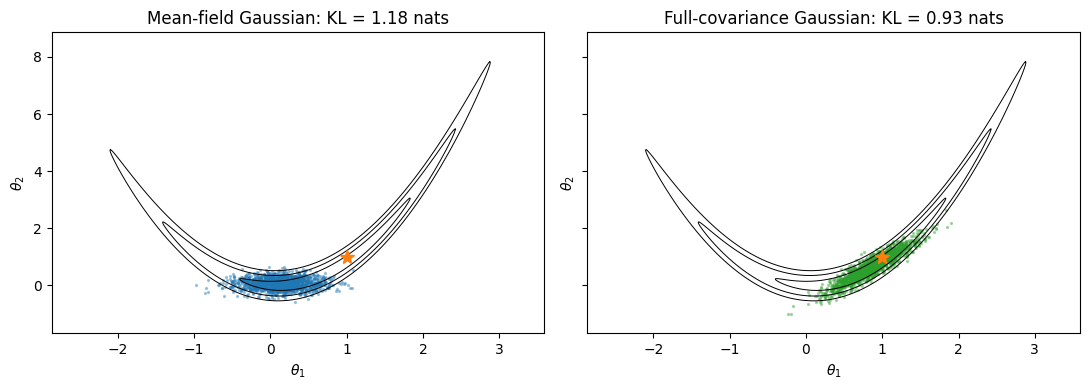

In [10]:
torch.manual_seed(0)
full = GaussianGroup("theta", 2, prior=prior)
with torch.no_grad():
    full.mean.copy_(theta_map)
t0 = time.time()
hist_full = train(full, surrogate, **GAUSS_CFG)
kl_full = exact_kl_gaussian(full)
print(f"trained in {time.time() - t0:.1f}s,  KL(q || p) = {kl_full:.3f} nats")

with torch.no_grad():
    theta_iid = mean_field.variational_distribution().sample((4000,))
    theta_full = full.variational_distribution().sample((4000,))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, th, kind, kl in [(axes[0], theta_iid, "iid", kl_iid), (axes[1], theta_full, "full", kl_full)]:
    exact_contours(ax)
    ax.scatter(th[:1500, 0], th[:1500, 1], s=2, alpha=0.35, color=COLORS[kind])
    ax.set_title(f"{LABELS[kind]}: KL = {kl:.2f} nats")
plt.tight_layout()

### Is that the best a Gaussian can do?

A large KL could mean the Gaussian is the wrong shape, or that training did
not converge. To separate the two, we fit the best Gaussian of each kind
*directly* against the exact log density (reparameterized samples, 3000 Adam
steps), without pypolymix. Nothing can push a Gaussian below this *family
ceiling*. If the trained KL matches it, the remaining error is the Gaussian
shape itself.

In [11]:
def gaussian_ceiling(diag, steps=3000, seed=0):
    g = torch.Generator().manual_seed(seed)
    eps = torch.randn(8192, 2, generator=g)
    mu = theta_exact.mean(0).clone().requires_grad_(True)
    L0 = torch.linalg.cholesky(torch.cov(theta_exact.T))
    raw = (L0.diagonal().log() if diag else L0).clone().requires_grad_(True)
    opt = torch.optim.Adam([mu, raw], lr=0.01)

    def scale():
        if diag:
            return torch.diag(raw.exp())
        Lt = torch.tril(raw)
        return Lt - torch.diag(Lt.diagonal()) + torch.diag(Lt.diagonal().abs() + 1e-12)

    def kl(e):
        S = scale()
        entropy = (1 + LOG2PI) + S.diagonal().log().sum()
        return (-log_joint(mu + e @ S.T)).mean() - entropy + logZ

    for _ in range(steps):
        opt.zero_grad()
        kl(eps).backward()
        opt.step()
    with torch.no_grad():
        return kl(torch.randn(200_000, 2, generator=g)).item()


ceiling = {"iid": gaussian_ceiling(diag=True), "full": gaussian_ceiling(diag=False)}
print(f"mean-field:       trained KL {kl_iid:.3f}   ceiling {ceiling['iid']:.3f}")
print(f"full-covariance:  trained KL {kl_full:.3f}   ceiling {ceiling['full']:.3f}")

mean-field:       trained KL 1.178   ceiling 1.173
full-covariance:  trained KL 0.931   ceiling 0.930


## Langevin

`LangevinGroup` has no density formula. It defines $q$ by a *procedure*:
start particles from $N(0, I)$ and run $K$ steps of unadjusted Langevin
dynamics
$$z^{(k+1)} = z^{(k)} + h\, s_\phi\big(z^{(k)}\big) + \sqrt{2h}\,\xi^{(k)},\qquad \xi^{(k)} \sim N(0, I),$$
where the drift $s_\phi$ is learned (the *score network*).
The particles after $K$ steps are the samples of $q$. Training
backpropagates the ELBO through all $K$ steps into the network weights
$\phi$. Since $q$ has no density, `KNNEntropyKL` estimates the KL to the
prior from the particles with a nearest-neighbour entropy estimate.

**Preconditioning.** Every step adds noise with standard deviation
$\sqrt{2h}$ (0.1 for the $h = 0.005$ used below), which is wider than the thin direction of the
banana, so in raw coordinates the particles could never get thin enough.
We therefore run the dynamics in coordinates $z$ with a *fixed* affine map
$\theta = m + Lz$, where $(m, LL^\top)$ is the trained full-covariance
Gaussian, and give the group the exact image of the prior under that map.
KL is unchanged by a fixed invertible map, so the problem is the same. The
particles start out as $z \sim N(0, I)$, which is exactly the
full-covariance Gaussian in $\theta$.

Once trained, drawing samples costs $K$ evaluations of the small score
network: nothing in the sampler evaluates the model or the data.

The map is a thin `SurrogateModel` wrapper, so the training loop is unchanged.

In [12]:
class Affine(SurrogateModel):
    # evaluate the base surrogate at theta = m + L z
    num_inputs, num_outputs = 1, 1

    def __init__(self, base, m, L):
        super().__init__()
        self.base = base
        self.register_buffer("m", m.clone())
        self.register_buffer("L", L.clone())

    def forward(self, x, z):
        return self.base(x, self.m + z @ self.L.T)

    def num_params(self):
        return self.base.num_params()


q_full = full.variational_distribution()
m, L = q_full.mean.detach(), q_full.scale_tril.detach()
Linv = torch.linalg.inv(L)
prior_z = GaussianPrior(-Linv @ m, covariance_matrix=PRIOR_STD**2 * Linv @ Linv.T)  # N(0, 3^2 I) seen in z


def z_to_theta(z):
    return m + z @ L.T


def make_langevin(seed):
    torch.manual_seed(seed)
    score = NeuralNetwork(num_inputs=2, num_outputs=2, width=WIDTH, depth=2, activation=F.tanh)
    return LangevinGroup("z", 2, score_model=score, prior=prior_z, num_particles=128, num_diffusion_steps=NUM_STEPS,
                         step_size=STEP, init_std=1.0, kl_estimator=KNNEntropyKL(k=4))

### Choosing the step size and the pseudotime

Two things limit the step size $h$, and both depend on the posterior's shape
in the coordinates $z$ where the dynamics run:

* **Noise floor.** Every step adds noise of standard deviation $\sqrt{2h}$.
  The drift can pull particles back, but not by more than one step's worth,
  so the final cloud can never be thinner than about $\sqrt{2h}$. This must
  be smaller than the thinnest part of the posterior: $h \le w^2/2$, where
  $w$ is the local width.
* **Stability.** Where the posterior is stiff (local curvature $\lambda$ of
  $-\log p$), a drift that follows the score overshoots once
  $h > 2/\lambda$.

Both quantities come from the Hessian of $-\log p$ at exact posterior
samples. The local width in the stiffest direction is
$w = 1/\sqrt{\lambda_{\max}}$. We take the thinnest 5% of the posterior and
its stiffest 1%.

The *pseudotime* $T = Kh$ is the total time the particles travel. Following
common practice we use $T = 2$, with a step size well inside both limits:
$h = 0.005$, so $K = 400$ steps. The next cell sets these values (and the
other Langevin settings and the seeds), and the cell after it prints both
limits for this posterior.

In [13]:
STEP = 5e-3  # step size h
NUM_STEPS = 400  # K, so the pseudotime is T = K h = 2
WIDTH = 64  # hidden width of the score network
NUM_EPOCHS = 6000
SEEDS = [0, 1, 2]

In [14]:
z_probe = torch.linalg.solve_triangular(L, (theta_exact[:500] - m).T, upper=False).T
lam_max = torch.stack([
    torch.linalg.eigvalsh(torch.autograd.functional.hessian(lambda z: -log_joint(z_to_theta(z[None]))[0], z)).max()
    for z in z_probe
])
w05, lam99 = lam_max.rsqrt().quantile(0.05).item(), lam_max.quantile(0.99).item()
print(f"thinnest 5%: local width w = {w05:.3f}   ->  noise floor  h <= w^2/2      = {w05**2 / 2:.4f}")
print(f"stiffest 1%: curvature   = {lam99:.1f}   ->  stability    h <  2/curvature = {2 / lam99:.4f}")
print(f"chosen: h = {STEP}, K = {NUM_STEPS} steps, pseudotime T = {NUM_STEPS * STEP:g}")

thinnest 5%: local width w = 0.167   ->  noise floor  h <= w^2/2      = 0.0140
stiffest 1%: curvature   = 59.4   ->  stability    h <  2/curvature = 0.0337
chosen: h = 0.005, K = 400 steps, pseudotime T = 2


### Training

Each epoch runs the $K$ steps for 128 particles and backpropagates the ELBO
through all of them into the score network ($2 \to 64 \to 64 \to 2$, tanh).
We train for 6000 epochs at a learning rate of $5\cdot10^{-3}$ with gradient
clipping, and use three seeds to check that the result does not depend on
the initialization.

One run takes about 35 minutes, so each run (trained state plus 4000
samples) is cached on disk by `_cache_utils.CacheDir`, under a key that
includes all Langevin settings. Delete the cache directory to retrain.
Because these settings and the seeds are set in the `parameters` cell above,
the seeds can be trained in parallel (for example with papermill, one seed
per process) and then collected from the cache.

In [15]:
for _candidate in [pathlib.Path("docs/examples"), pathlib.Path(".")]:
    if (_candidate / "_cache_utils.py").exists():
        sys.path.insert(0, str(_candidate))
        CACHE_DIR = _candidate / ".cache" / "rosenbrock_banana_posterior"
        break
else:
    raise RuntimeError("Could not locate _cache_utils.py -- run from the repo root or docs/examples/.")
from _cache_utils import CacheDir

cache = CacheDir(CACHE_DIR)

LANGEVIN_CFG = dict(num_epochs=NUM_EPOCHS, num_samples=128, lr=5e-3, clip=10.0)
langevin = {}
for seed in SEEDS:
    def _train(seed=seed):
        group = make_langevin(seed)
        t0 = time.time()
        hist = train(group, Affine(surrogate, m, L), seed=seed, **LANGEVIN_CFG)
        torch.manual_seed(1000 + seed)
        with torch.no_grad():
            z = group.sample_parameters(4000)
        return dict(state_dict=group.state_dict(), hist=hist, z=z, time=time.time() - t0)

    key = f"langevin_h{STEP:g}_K{NUM_STEPS}_w{WIDTH}_e{NUM_EPOCHS}_seed{seed}"
    run = cache.get(key, _train)
    group = make_langevin(seed)
    group.load_state_dict(run["state_dict"])
    langevin[seed] = dict(run, group=group, theta=z_to_theta(run["z"]))

[cache hit]  langevin_h0.005_K400_w64_e6000_seed0  <-  langevin_h0.005_K400_w64_e6000_seed0.pt
[cache hit]  langevin_h0.005_K400_w64_e6000_seed1  <-  langevin_h0.005_K400_w64_e6000_seed1.pt
[cache hit]  langevin_h0.005_K400_w64_e6000_seed2  <-  langevin_h0.005_K400_w64_e6000_seed2.pt


### Measuring the KL without a density

$\mathrm{KL}(q\,\|\,p) = \mathbb{E}_q[-\log p(\theta\mid y)] - H[q]$. The first
term is exact, because we know $\log p$. The entropy $H[q]$ is estimated with
the kNN estimator on the 4000 samples, computed in the whitened coordinates.
To measure the estimator's bias, we apply it to 4000 *exact* samples, whose
entropy we know, and subtract that bias. As a check, we apply the same
procedure to the full-covariance Gaussian, whose KL we know exactly.

In [16]:
LOG_DET_L = L.diagonal().abs().log().sum().item()


def knn_entropy(theta, k=4):
    z = torch.linalg.solve_triangular(L, (theta - m).T, upper=False).T
    return _knn_entropy(z, k=k).item() + LOG_DET_L


KNN_BIAS = knn_entropy(theta_exact[:4000]) - H_exact


def kl_knn(theta):
    with torch.no_grad():
        cross_entropy = -(log_joint(theta) - logZ).mean().item()
    return cross_entropy - knn_entropy(theta) + KNN_BIAS


print(f"kNN entropy bias on exact samples: {KNN_BIAS:+.3f} nats")
print(f"check on the full Gaussian: kNN estimate {kl_knn(theta_full):.3f}  vs  exact {kl_full:.3f}")
for seed in SEEDS:
    langevin[seed]["kl"] = kl_knn(langevin[seed]["theta"])
    print(f"Langevin seed {seed}: KL(q || p) = {langevin[seed]['kl']:.3f} nats")
kl_lang = np.array([langevin[s]["kl"] for s in SEEDS])
SHOW = SEEDS[int(np.argsort(kl_lang)[len(SEEDS) // 2])]  # the median seed, used in the plots
print(f"mean over seeds: {kl_lang.mean():.3f} +/- {kl_lang.std(ddof=1):.3f}")

kNN entropy bias on exact samples: +0.007 nats


check on the full Gaussian: kNN estimate 0.931  vs  exact 0.931


Langevin seed 0: KL(q || p) = 0.285 nats


Langevin seed 1: KL(q || p) = 0.198 nats


Langevin seed 2: KL(q || p) = 0.512 nats
mean over seeds: 0.332 +/- 0.162


### Watching the particles move

`sample_trajectory` runs the trained dynamics and records every step. The
particles start from $N(0, I)$ in the whitened coordinates $z$, which is the
full-covariance Gaussian in $\theta$. Below, 40 individual particle paths,
each coordinate of $z$ against pseudotime $t = kh$. The left strip is the
starting distribution $N(0, 1)$. The right strip compares the particles at
the end time (histogram) with the exact posterior marginal (grey). The shaded
band is the central 90% of 2000 particles.

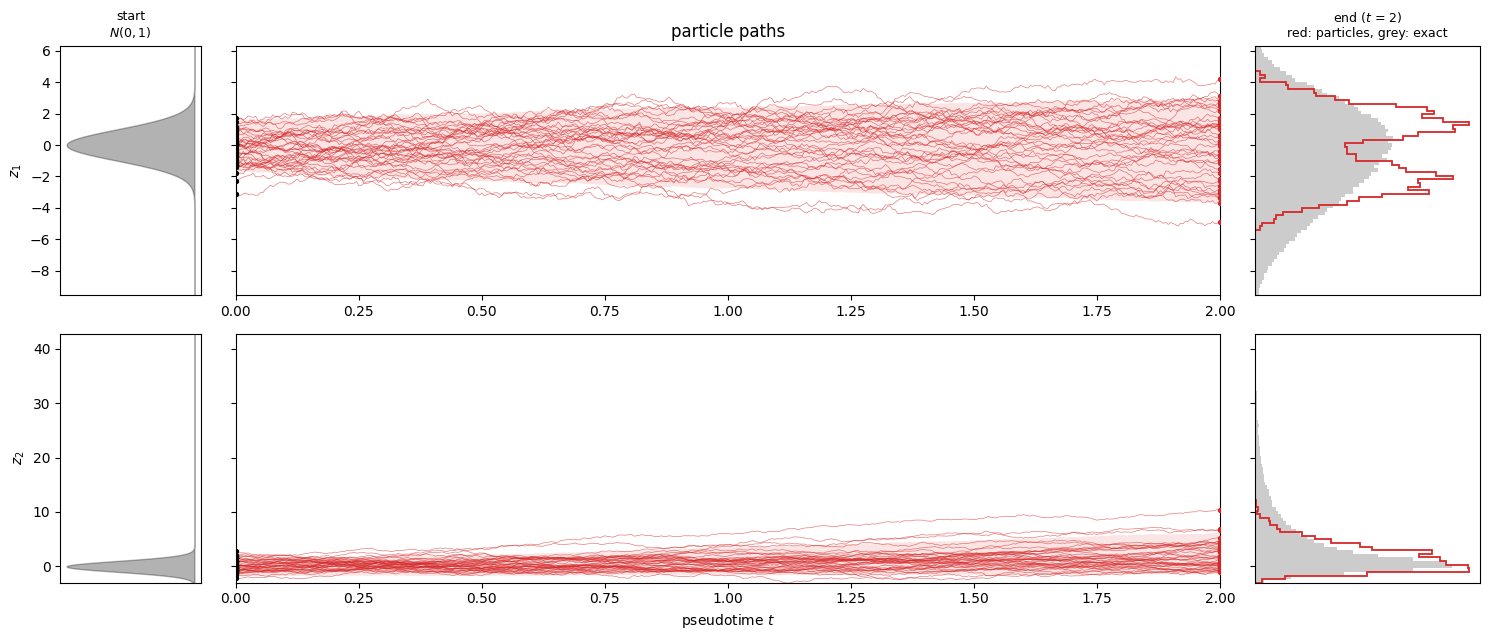

In [17]:
torch.manual_seed(0)
with torch.no_grad():
    traj_z = langevin[SHOW]["group"].sample_trajectory(2000, record_every=1)  # (K_MAX + 1, 2000, 2)
traj = z_to_theta(traj_z)
t_axis = np.arange(traj_z.shape[0]) * STEP
z_exact = torch.linalg.solve_triangular(L, (theta_exact - m).T, upper=False).T

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 7, 1.6]}, sharey="row")
for j in range(2):
    ax_start, ax, ax_end = axes[j]
    lo_j, hi_j = [v.item() for v in torch.quantile(z_exact[:, j], torch.tensor([0.002, 0.998]))]
    lo_j, hi_j = min(lo_j, -3.0), max(hi_j, 3.0)
    band = torch.quantile(traj_z[:, :, j], torch.tensor([0.05, 0.95]), dim=1)
    ax.fill_between(t_axis, band[0], band[1], color=COLORS["langevin"], alpha=0.12, lw=0)
    for p in range(40):
        ax.plot(t_axis, traj_z[:, p, j], color=COLORS["langevin"], lw=0.5, alpha=0.6)
    ax.scatter(np.zeros(40), traj_z[0, :40, j], s=8, color="k", zorder=3)
    ax.scatter(np.full(40, t_axis[-1]), traj_z[-1, :40, j], s=8, color=COLORS["langevin"], zorder=3)
    ax.set_xlim(0, t_axis[-1])
    ax.set_ylim(lo_j, hi_j)
    zz = np.linspace(lo_j, hi_j, 300)
    ax_start.fill_betweenx(zz, 0, np.exp(-0.5 * zz**2) / math.sqrt(2 * math.pi), color="k", alpha=0.3)
    ax_start.invert_xaxis()
    ax_start.set_ylabel(f"$z_{j + 1}$")
    bins = np.linspace(lo_j, hi_j, 70)
    ax_end.hist(z_exact[:, j].numpy(), bins=bins, density=True, orientation="horizontal", color="0.8")
    ax_end.hist(traj_z[-1, :, j].numpy(), bins=bins, density=True, orientation="horizontal", histtype="step",
                color=COLORS["langevin"], lw=1.3)
    for a_ in (ax_start, ax_end):
        a_.set_xticks([])
axes[0, 0].set_title("start\n$N(0, 1)$", fontsize=9)
axes[0, 1].set_title("particle paths")
axes[0, 2].set_title(f"end ($t$ = {t_axis[-1]:g})\nred: particles, grey: exact", fontsize=9)
axes[1, 1].set_xlabel("pseudotime $t$")
plt.tight_layout()

The same paths in the plane: in the whitened coordinates $z$, where they
start from $N(0, I)$ (left), and mapped to the model parameters $\theta$
(right). Black dots are starting points and red dots are end points. The
contours are the exact posterior in each set of coordinates.

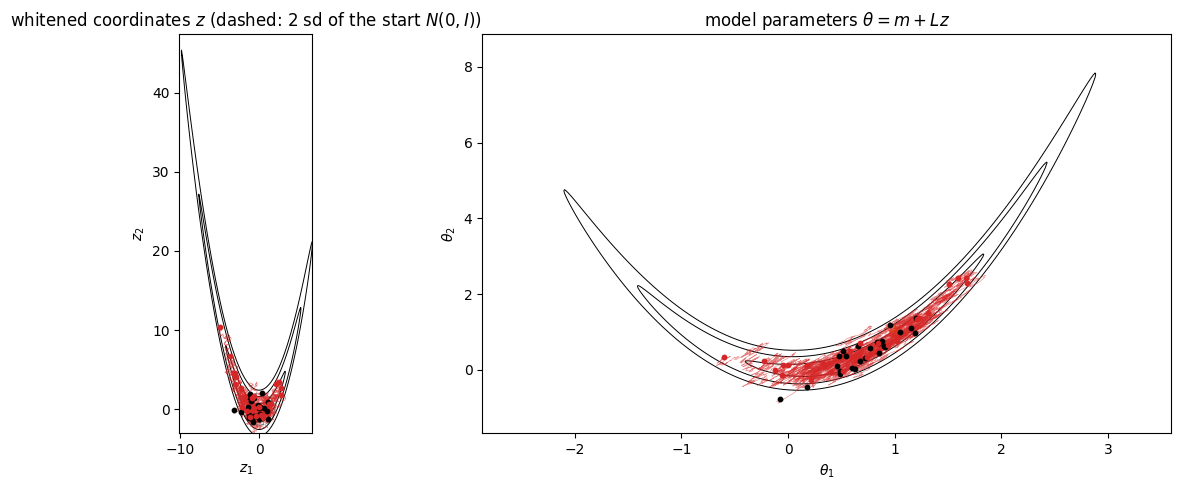

In [18]:
# exact posterior contours in z: evaluate log p on a z-grid (the Jacobian of the affine map is constant)
zq = torch.quantile(z_exact, torch.tensor([0.001, 0.999]), dim=0)
z1 = torch.linspace(min(zq[0, 0].item(), -3.0), max(zq[1, 0].item(), 3.0), 400)
z2 = torch.linspace(min(zq[0, 1].item(), -3.0), max(zq[1, 1].item(), 3.0), 400)
Z1, Z2 = torch.meshgrid(z1, z2, indexing="ij")
with torch.no_grad():
    dens_z = log_joint(z_to_theta(torch.stack([Z1.flatten(), Z2.flatten()], 1))).reshape(400, 400)
dens_z = (dens_z - dens_z.max()).exp()
_dz = dens_z.flatten().sort(descending=True).values
_cz = _dz.cumsum(0) / _dz.sum()
levels_z = [_dz[(_cz >= q).nonzero()[0, 0]].item() for q in (0.99, 0.9, 0.5)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].contour(z1, z2, dens_z.T, levels=levels_z, colors="k", linewidths=0.7)
axes[0].add_patch(plt.Circle((0, 0), 2.0, fill=False, ls="--", color="0.5"))
exact_contours(axes[1])
for ax, tr in [(axes[0], traj_z), (axes[1], traj)]:
    for p in range(25):
        ax.plot(tr[:, p, 0], tr[:, p, 1], color=COLORS["langevin"], lw=0.4, alpha=0.6)
    ax.scatter(tr[0, :25, 0], tr[0, :25, 1], s=10, color="k", zorder=3)
    ax.scatter(tr[-1, :25, 0], tr[-1, :25, 1], s=10, color=COLORS["langevin"], zorder=3)
axes[0].set_xlim(z1[0], z1[-1])
axes[0].set_ylim(z2[0], z2[-1])
axes[0].set_aspect("equal")
axes[0].set_xlabel("$z_1$")
axes[0].set_ylabel("$z_2$")
axes[0].set_title("whitened coordinates $z$ (dashed: 2 sd of the start $N(0, I)$)")
axes[1].set_title(r"model parameters $\theta = m + L z$")
plt.tight_layout()

Snapshots of the whole cloud at a few pseudotimes:

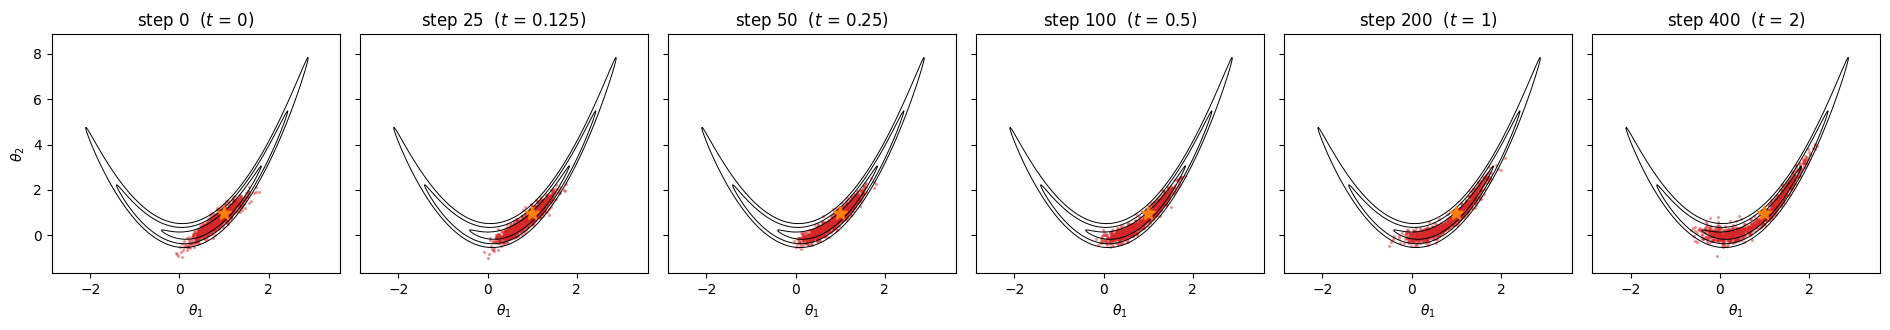

In [19]:
snap_steps = [0] + [NUM_STEPS // d for d in (16, 8, 4, 2, 1)]
fig, axes = plt.subplots(1, len(snap_steps), figsize=(19, 3.4), sharex=True, sharey=True)
for ax, k in zip(axes, snap_steps):
    exact_contours(ax)
    ax.scatter(traj[k, :1000, 0], traj[k, :1000, 1], s=2, alpha=0.35, color=COLORS["langevin"])
    ax.set_title(f"step {k}  ($t$ = {k * STEP:g})")
for ax in axes[1:]:
    ax.set_ylabel("")
plt.tight_layout()

### How far did the particles get?

The KL to the exact posterior against pseudotime, for each seed, measured
on 4000 particles with the same bias-corrected estimator as above. At
$t = 0$ the particles are the full-covariance Gaussian, so every curve
starts at that family's KL. Solid: the training horizon $T$. Dashed: the
same dynamics continued to $2T$, which they were never trained for.

The trained sampler is built to deliver the posterior at its end time $T$.
It is not a stationary sampler, so there is no guarantee that the particles
stay put after $T$.

trained Langevin at t = 2:  KL = 0.328  (seeds [0.305 0.168 0.511])


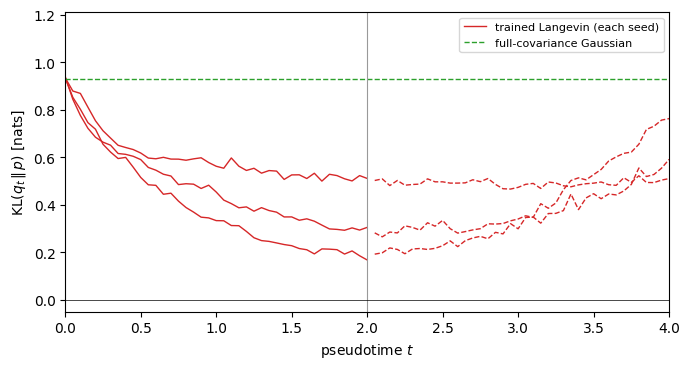

In [20]:
kl_t = {}
for seed in SEEDS:
    group = langevin[seed]["group"]
    group.num_diffusion_steps = 2 * NUM_STEPS
    torch.manual_seed(2000 + seed)
    with torch.no_grad():
        tz = group.sample_trajectory(4000, record_every=NUM_STEPS // 40)
    group.num_diffusion_steps = NUM_STEPS
    kl_t[seed] = np.array([kl_knn(z_to_theta(z)) for z in tz])
t_lang = np.arange(len(kl_t[SEEDS[0]])) * (NUM_STEPS // 40) * STEP
T = NUM_STEPS * STEP

fig, ax = plt.subplots(figsize=(7, 3.8))
inside = t_lang <= T + 1e-9
for seed in SEEDS:
    ax.plot(t_lang[inside], kl_t[seed][inside], color=COLORS["langevin"], lw=1,
            label="trained Langevin (each seed)" if seed == SEEDS[0] else None)
    ax.plot(t_lang[~inside], kl_t[seed][~inside], color=COLORS["langevin"], lw=1, ls="--")
ax.axhline(kl_full, color=COLORS["full"], ls="--", lw=1, label="full-covariance Gaussian")
ax.axvline(T, color="0.6", lw=0.8)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlim(0, 2 * T)
ax.set_ylim(-0.05, 1.3 * kl_full)
ax.set_xlabel("pseudotime $t$")
ax.set_ylabel(r"KL$(q_t\,\|\,p)$ [nats]")
ax.legend(fontsize=8)
plt.tight_layout()

kl_T = np.array([kl_t[s][np.argmin(np.abs(t_lang - T))] for s in SEEDS])
print(f"trained Langevin at t = {T:g}:  KL = {kl_T.mean():.3f}  (seeds {np.round(kl_T, 3)})")

## Comparison

All three families against the exact posterior: samples over the exact
contours, then the marginals and the training curves ($N \cdot$ loss
$+ \log Z$, the running KL estimate).

                             KL(q || p)   ceiling
Mean-field Gaussian               1.178     1.173
Full-covariance Gaussian          0.931     0.930
Langevin                          0.332   (+/- 0.162 over 3 seeds)


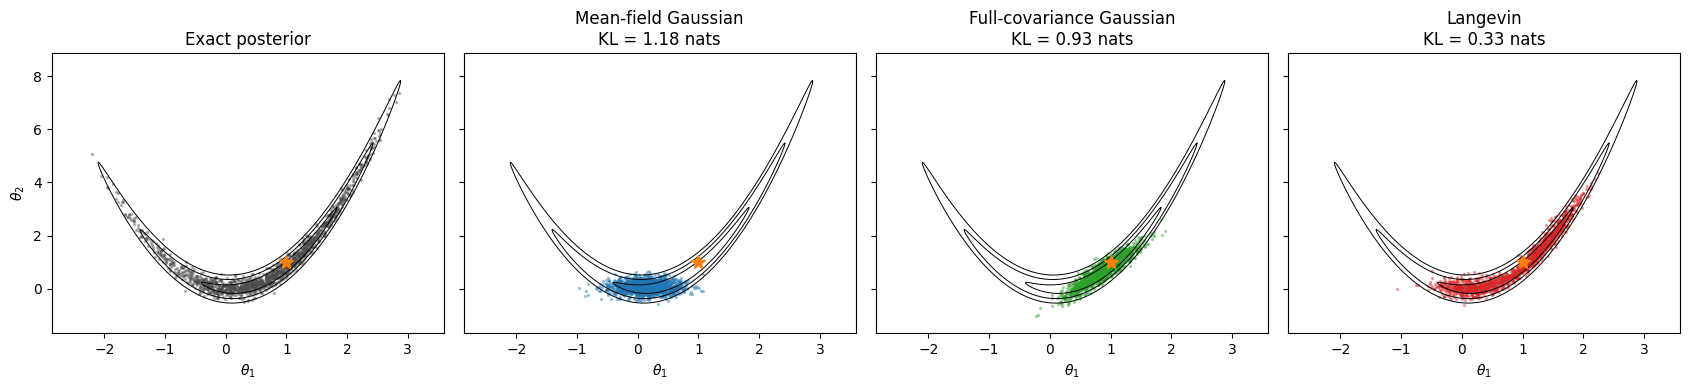

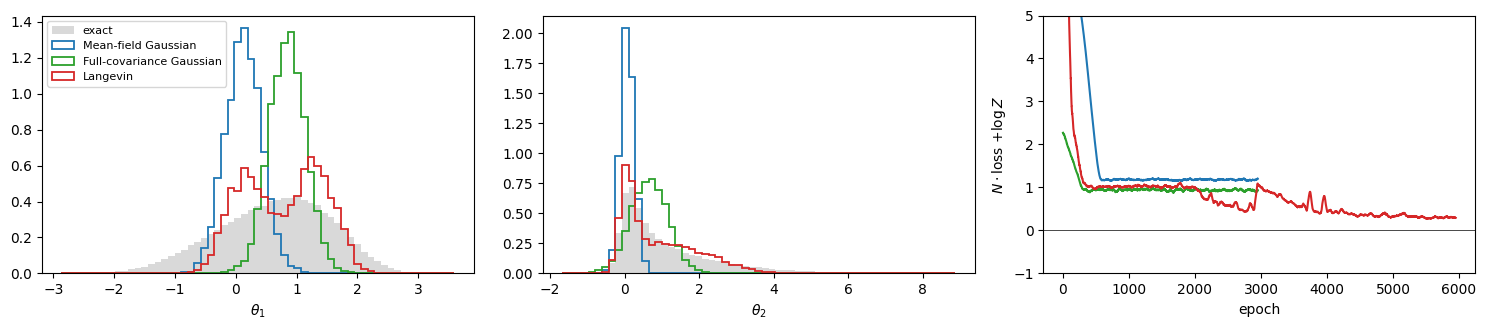

In [21]:
samples = {"exact": theta_exact[:4000], "iid": theta_iid, "full": theta_full, "langevin": langevin[SHOW]["theta"]}
kls = {"iid": kl_iid, "full": kl_full, "langevin": kl_lang.mean()}

fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, (kind, th) in zip(axes, samples.items()):
    exact_contours(ax)
    ax.scatter(th[:1500, 0], th[:1500, 1], s=2, alpha=0.35, color=COLORS[kind])
    ax.set_title(LABELS[kind] + ("" if kind == "exact" else f"\nKL = {kls[kind]:.2f} nats"))
for ax in axes[1:]:
    ax.set_ylabel("")
plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for j, ax in enumerate(axes[:2]):
    bins = np.linspace(*PLOT_LIMS[j], 60)
    ax.hist(theta_exact[:, j].numpy(), bins=bins, density=True, color="0.85", label="exact")
    for kind in ["iid", "full", "langevin"]:
        ax.hist(samples[kind][:, j].numpy(), bins=bins, density=True, histtype="step", lw=1.3, color=COLORS[kind],
                label=LABELS[kind])
    ax.set_xlabel(NAMES[j])
axes[0].legend(fontsize=8)
smooth = lambda h: np.convolve(h, np.ones(50) / 50, mode="valid") + logZ
for kind, h in [("iid", hist_iid), ("full", hist_full), ("langevin", langevin[SHOW]["hist"])]:
    axes[2].plot(smooth(h), color=COLORS[kind], label=LABELS[kind])
axes[2].axhline(0, color="k", lw=0.5)
axes[2].set_ylim(-1, 5)
axes[2].set_xlabel("epoch")
axes[2].set_ylabel(r"$N\cdot$loss $+\log Z$")
plt.tight_layout()

print(f"{'':26s} {'KL(q || p)':>12s} {'ceiling':>9s}")
print(f"{LABELS['iid']:26s} {kl_iid:12.3f} {ceiling['iid']:9.3f}")
print(f"{LABELS['full']:26s} {kl_full:12.3f} {ceiling['full']:9.3f}")
print(f"{LABELS['langevin']:26s} {kl_lang.mean():12.3f}   (+/- {kl_lang.std(ddof=1):.3f} over {len(SEEDS)} seeds)")